# Pemodelan Klasifikasi Risiko PM2.5

## 1. Tujuan Pemodelan

Pemodelan ini bertujuan memprediksi kategori risiko kualitas udara pada hari berikutnya untuk setiap kabupaten/kota di Pulau Jawa.

Kategori risiko ditentukan berdasarkan nilai target PM2.5:

- Baik (Aman): PM2.5 ≤ 15 µg/m³
- Sedang (Waspada): 15 < PM2.5 ≤ 55 µg/m³
- Tidak Sehat (Bahaya): PM2.5 > 55 µg/m³

## 2. Rumusan Masalah

Berdasarkan kondisi kualitas udara dan histori beberapa hari sebelumnya, apakah kondisi PM2.5 pada hari berikutnya dapat diklasifikasikan ke dalam kategori Baik, Sedang, atau Tidak Sehat?

## 3. Unit Analisis

Satu baris data merepresentasikan satu kabupaten/kota pada satu tanggal.

Contoh:

- Wilayah: Kota Bekasi
- Tanggal: 2025-01-01
- Fitur: kondisi PM2.5 dan polutan pada tanggal tersebut serta histori sebelumnya
- Target: kategori risiko PM2.5 pada tanggal berikutnya

## 4. Jenis Masalah

Masalah ini merupakan klasifikasi multiclass dengan tiga kelas:

1. Baik (Aman)
2. Sedang (Waspada)
3. Tidak Sehat (Bahaya)

Model klasifikasi akan digunakan sebagai pendekatan langsung untuk memprediksi kategori risiko.

Sebagai pembanding, pendekatan regresi forecasting juga dapat digunakan dengan cara:

1. Memprediksi nilai PM2.5 hari berikutnya.
2. Mengubah nilai prediksi tersebut menjadi kategori risiko.

## 5. Tujuan Evaluasi

Evaluasi tidak hanya berfokus pada accuracy karena distribusi kelas tidak seimbang. Metrik utama yang digunakan adalah:

- Precision setiap kelas
- Recall setiap kelas
- F1-score setiap kelas
- Macro F1-score
- Balanced accuracy
- Confusion matrix

Perhatian khusus diberikan pada recall kelas Baik dan Tidak Sehat karena kedua kelas tersebut lebih sedikit dibandingkan kelas Sedang.


# Import Library

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    recall_score, classification_report, confusion_matrix
)
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

# Membaca Dataset

In [10]:
path_data = Path("../../data/data_gabungan/airguard_preprocessed.csv")

df = pd.read_csv(
    path_data,
    parse_dates=["tanggal"]
)

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


# Pemeriksaan ukuran dan periode

In [11]:
print("Ukuran dataset:", df.shape)
print("Periode:", df["tanggal"].min().date(), "sampai", df["tanggal"].max().date())
print("Jumlah kabupaten/kota:", df["nama_kabkota"].nunique())
print("Jumlah provinsi:", df["provinsi"].nunique())

Ukuran dataset: (181594, 26)
Periode: 2022-08-18 sampai 2026-10-21
Jumlah kabupaten/kota: 119
Jumlah provinsi: 6


# Melihat struktur kolom

In [12]:
display(df.head())

print("Daftar kolom:")
print(df.columns.tolist())

print("\nTipe data:")
display(df.dtypes)

,kode_kabkota,nama_kabkota,provinsi,tipe,latitude,longitude,elevasi_m,luas_km2,penduduk,tanggal,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,pm2_5_lag_1,pm2_5_lag_2,pm2_5_lag_3,pm2_5_lag_7,pm2_5_lag_14,pm2_5_rolling_3,pm2_5_rolling_7,pm2_5_rolling_14,target_pm2_5,kategori_target_pm2_5
0,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-18,36.625000,22.025000,355.333333,5.283333,4.895833,112.125000,22.691667,16.329167,15.075000,18.687500,25.705882,20.348611,19.065476,20.370238,21.333333,Sedang (Waspada)
1,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-19,35.900000,21.333333,306.250000,3.875000,4.629167,118.750000,22.025000,22.691667,16.329167,17.145833,9.258333,22.016667,19.663690,21.232738,23.479167,Sedang (Waspada)
2,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-20,39.495833,23.479167,289.708333,3.608333,4.645833,111.375000,21.333333,22.025000,22.691667,22.412500,21.075000,22.279167,19.816071,21.404464,27.037500,Sedang (Waspada)
3,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-21,44.529167,27.037500,477.708333,9.495833,9.620833,129.208333,23.479167,21.333333,22.025000,17.779167,27.645833,23.950000,21.138690,21.361012,18.487500,Sedang (Waspada)
4,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-22,31.383333,18.487500,350.500000,2.020833,5.220833,128.666667,27.037500,23.479167,21.333333,15.075000,36.504167,23.001389,21.626190,20.074107,27.937500,Sedang (Waspada)


Daftar kolom:
['kode_kabkota', 'nama_kabkota', 'provinsi', 'tipe', 'latitude', 'longitude', 'elevasi_m', 'luas_km2', 'penduduk', 'tanggal', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'pm2_5_lag_1', 'pm2_5_lag_2', 'pm2_5_lag_3', 'pm2_5_lag_7', 'pm2_5_lag_14', 'pm2_5_rolling_3', 'pm2_5_rolling_7', 'pm2_5_rolling_14', 'target_pm2_5', 'kategori_target_pm2_5']

Tipe data:


kode_kabkota                    float64
nama_kabkota                     object
provinsi                         object
tipe                             object
latitude                        float64
longitude                       float64
elevasi_m                       float64
luas_km2                        float64
penduduk                        float64
tanggal                  datetime64[ns]
pm10                            float64
pm2_5                           float64
carbon_monoxide                 float64
nitrogen_dioxide                float64
sulphur_dioxide                 float64
ozone                           float64
pm2_5_lag_1                     float64
pm2_5_lag_2                     float64
pm2_5_lag_3                     float64
pm2_5_lag_7                     float64
pm2_5_lag_14                    float64
pm2_5_rolling_3                 float64
pm2_5_rolling_7                 float64
pm2_5_rolling_14                float64
target_pm2_5                    float64


# Cek missing value

In [13]:
missing_check = pd.DataFrame({
    "jumlah_missing": df.isna().sum(),
    "persentase_missing": df.isna().mean() * 100
})

missing_check = missing_check.sort_values(
    "jumlah_missing",
    ascending=False
)

display(missing_check)

,jumlah_missing,persentase_missing
kode_kabkota,0,0.0
nama_kabkota,0,0.0
provinsi,0,0.0
tipe,0,0.0
latitude,0,0.0
longitude,0,0.0
elevasi_m,0,0.0
luas_km2,0,0.0
penduduk,0,0.0
tanggal,0,0.0


# Memeriksa duplikasi wilayah dan tanggal

In [14]:
jumlah_duplikat = df.duplicated(
    subset=["nama_kabkota", "tanggal"]
).sum()

print("Jumlah duplikasi wilayah-tanggal:", jumlah_duplikat)

Jumlah duplikasi wilayah-tanggal: 0


# Memeriksa distribusi target

In [15]:
target = "kategori_target_pm2_5"
distribusi_target = (
    df[target]
    .value_counts()
    .rename_axis("kategori")
    .reset_index(name="jumlah")
)

distribusi_target["persentase"] = (
    distribusi_target["jumlah"]
    / distribusi_target["jumlah"].sum()
    * 100
)

distribusi_target["persentase"] = (
    distribusi_target["persentase"]
    .round(2)
)

display(distribusi_target)

,kategori,jumlah,persentase
0,Sedang (Waspada),118774,65.41
1,Tidak Sehat (Bahaya),35858,19.75
2,Baik (Aman),26962,14.85


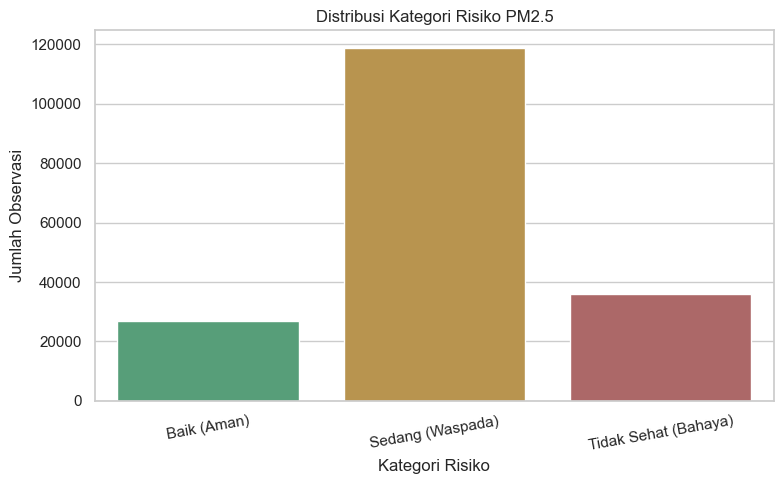

In [16]:
urutan_kategori = [
    "Baik (Aman)",
    "Sedang (Waspada)",
    "Tidak Sehat (Bahaya)"
]

warna_kategori = {
    "Baik (Aman)": "#4BAA78",
    "Sedang (Waspada)": "#C99A3E",
    "Tidak Sehat (Bahaya)": "#B85C5C"
}

plt.figure(figsize=(8, 5))

sns.barplot(
    data=distribusi_target,
    x="kategori",
    y="jumlah",
    order=urutan_kategori,
    hue="kategori",
    palette=warna_kategori,
    legend=False
)

plt.title("Distribusi Kategori Risiko PM2.5")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Observasi")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Memeriksa distribusi target per periode

In [17]:
target = "kategori_target_pm2_5"
urutan_kategori = [
    "Baik (Aman)", 
    "Sedang (Waspada)", 
    "Tidak Sehat (Bahaya)"
]

# Ensure 'tanggal' is datetime type first (just in case)
df["tanggal"] = pd.to_datetime(df["tanggal"])

distribusi_tahunan = pd.crosstab(
    df["tanggal"].dt.year,
    df[target],
    normalize="index"
) * 100

distribusi_tahunan = distribusi_tahunan.reindex(
    columns=urutan_kategori
)

display(distribusi_tahunan.round(2))

kategori_target_pm2_5,Baik (Aman),Sedang (Waspada),Tidak Sehat (Bahaya)
tanggal,,,
2022,29.20,63.95,6.85
2023,21.52,69.68,8.80
2024,20.83,65.92,13.25
2025,4.94,61.78,33.28
2026,4.77,64.64,30.59


# Menentukan Target

In [18]:
target = "kategori_target_pm2_5"

y = df[target].copy()

print("Nama target:", target)
print("Jumlah kelas:", y.nunique())
print("Kelas:", y.unique())

Nama target: kategori_target_pm2_5
Jumlah kelas: 3
Kelas: ['Sedang (Waspada)' 'Baik (Aman)' 'Tidak Sehat (Bahaya)']


# Menentukan fitur

In [19]:
fitur_model = [
    # Variabel geografis
    "latitude",
    "longitude",
    "elevasi_m",
    "luas_km2",
    "penduduk",

    # Variabel kualitas udara saat ini
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",

    # Fitur lag
    "pm2_5_lag_1",
    "pm2_5_lag_2",
    "pm2_5_lag_3",
    "pm2_5_lag_7",
    "pm2_5_lag_14",

    # Fitur rolling
    "pm2_5_rolling_3",
    "pm2_5_rolling_7",
    "pm2_5_rolling_14",

    # Fitur kalender
    "tahun",
    "bulan",
    "hari_dalam_minggu",
    "hari_dalam_tahun",
    "akhir_pekan"
]

# Memastikan semua fitur tersedia

In [20]:
kolom_tidak_tersedia = [
    kolom for kolom in fitur_model
    if kolom not in df.columns
]

if kolom_tidak_tersedia:
    print("Kolom berikut belum tersedia:")
    print(kolom_tidak_tersedia)
else:
    print("Semua fitur tersedia.")

Kolom berikut belum tersedia:
['tahun', 'bulan', 'hari_dalam_minggu', 'hari_dalam_tahun', 'akhir_pekan']


In [21]:
# Pastikan tanggal bertipe datetime
df["tanggal"] = pd.to_datetime(df["tanggal"])

# Feature engineering kalender
df["tahun"] = df["tanggal"].dt.year
df["bulan"] = df["tanggal"].dt.month
df["hari_dalam_minggu"] = df["tanggal"].dt.dayofweek
df["hari_dalam_tahun"] = df["tanggal"].dt.dayofyear
df["akhir_pekan"] = (
    df["hari_dalam_minggu"] >= 5
).astype(int)

print("Fitur kalender berhasil dibuat.")

Fitur kalender berhasil dibuat.


In [22]:
fitur_kalender = [
    "tahun",
    "bulan",
    "hari_dalam_minggu",
    "hari_dalam_tahun",
    "akhir_pekan"
]

display(df[fitur_kalender].head())

,tahun,bulan,hari_dalam_minggu,hari_dalam_tahun,akhir_pekan
0,2022,8,3,230,0
1,2022,8,4,231,0
2,2022,8,5,232,1
3,2022,8,6,233,1
4,2022,8,0,234,0


# Split x dan y

In [23]:
X = df[fitur_model].copy()
y = df[target].copy()

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Ukuran X: (181594, 24)
Ukuran y: (181594,)


# Memeriksa fitur yang digunakan 

In [24]:
display(X.head())
display(y.head())

,latitude,longitude,elevasi_m,luas_km2,penduduk,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,pm2_5_lag_1,pm2_5_lag_2,pm2_5_lag_3,pm2_5_lag_7,pm2_5_lag_14,pm2_5_rolling_3,pm2_5_rolling_7,pm2_5_rolling_14,tahun,bulan,hari_dalam_minggu,hari_dalam_tahun,akhir_pekan
0,-5.746481,106.61316,8.0,10.951,30334.0,22.025000,36.625000,355.333333,5.283333,4.895833,112.125000,22.691667,16.329167,15.075000,18.687500,25.705882,20.348611,19.065476,20.370238,2022,8,3,230,0
1,-5.746481,106.61316,8.0,10.951,30334.0,21.333333,35.900000,306.250000,3.875000,4.629167,118.750000,22.025000,22.691667,16.329167,17.145833,9.258333,22.016667,19.663690,21.232738,2022,8,4,231,0
2,-5.746481,106.61316,8.0,10.951,30334.0,23.479167,39.495833,289.708333,3.608333,4.645833,111.375000,21.333333,22.025000,22.691667,22.412500,21.075000,22.279167,19.816071,21.404464,2022,8,5,232,1
3,-5.746481,106.61316,8.0,10.951,30334.0,27.037500,44.529167,477.708333,9.495833,9.620833,129.208333,23.479167,21.333333,22.025000,17.779167,27.645833,23.950000,21.138690,21.361012,2022,8,6,233,1
4,-5.746481,106.61316,8.0,10.951,30334.0,18.487500,31.383333,350.500000,2.020833,5.220833,128.666667,27.037500,23.479167,21.333333,15.075000,36.504167,23.001389,21.626190,20.074107,2022,8,0,234,0


0    Sedang (Waspada)
1    Sedang (Waspada)
2    Sedang (Waspada)
3    Sedang (Waspada)
4    Sedang (Waspada)
Name: kategori_target_pm2_5, dtype: object

# Menentukan periode split

In [25]:
# Pastikan data terurut berdasarkan tanggal dan wilayah
df = df.sort_values(
    ["tanggal", "nama_kabkota"]
).reset_index(drop=True)

tanggal_train_awal = pd.Timestamp("2022-08-18")
tanggal_train_akhir = pd.Timestamp("2024-12-31")

tanggal_val_awal = pd.Timestamp("2025-01-01")
tanggal_val_akhir = pd.Timestamp("2025-12-31")

tanggal_test_awal = pd.Timestamp("2026-01-01")
tanggal_test_akhir = pd.Timestamp("2026-10-21")

# Membuat mask split

In [26]:
mask_train = (
    (df["tanggal"] >= tanggal_train_awal) &
    (df["tanggal"] <= tanggal_train_akhir)
)

mask_val = (
    (df["tanggal"] >= tanggal_val_awal) &
    (df["tanggal"] <= tanggal_val_akhir)
)

mask_test = (
    (df["tanggal"] >= tanggal_test_awal) &
    (df["tanggal"] <= tanggal_test_akhir)
)

# Membagi x dan y 

In [27]:
X_train = X.loc[mask_train].copy()
y_train = y.loc[mask_train].copy()

X_val = X.loc[mask_val].copy()
y_val = y.loc[mask_val].copy()

X_test = X.loc[mask_test].copy()
y_test = y.loc[mask_test].copy()

# Memeriksa ukuran data

In [28]:
print("Ukuran data train:", X_train.shape, y_train.shape)
print("Ukuran data validation:", X_val.shape, y_val.shape)
print("Ukuran data test:", X_test.shape, y_test.shape)

Ukuran data train: (103173, 24) (103173,)
Ukuran data validation: (43435, 24) (43435,)
Ukuran data test: (34986, 24) (34986,)


# Memeriksa periode setiap subset

In [29]:
def cek_periode(nama, mask):
    data_subset = df.loc[mask]

    print(f"{nama}")
    print("Tanggal awal :", data_subset["tanggal"].min().date())
    print("Tanggal akhir:", data_subset["tanggal"].max().date())
    print("Jumlah baris :", len(data_subset))
    print()

cek_periode("TRAIN", mask_train)
cek_periode("VALIDATION", mask_val)
cek_periode("TEST", mask_test)

TRAIN
Tanggal awal : 2022-08-18
Tanggal akhir: 2024-12-31
Jumlah baris : 103173

VALIDATION
Tanggal awal : 2025-01-01
Tanggal akhir: 2025-12-31
Jumlah baris : 43435

TEST
Tanggal awal : 2026-01-01
Tanggal akhir: 2026-10-21
Jumlah baris : 34986



# Memeriksa distribusi kelas

In [30]:
def distribusi_kelas(nama, data_target):
    hasil = (
        data_target
        .value_counts()
        .reindex(urutan_kategori, fill_value=0)
        .rename_axis("kategori")
        .reset_index(name="jumlah")
    )

    hasil["persentase"] = (
        hasil["jumlah"]
        / hasil["jumlah"].sum()
        * 100
    ).round(2)

    hasil.insert(0, "subset", nama)

    return hasil

distribusi_split = pd.concat([
    distribusi_kelas("Train", y_train),
    distribusi_kelas("Validation", y_val),
    distribusi_kelas("Test", y_test)
], ignore_index=True)

display(distribusi_split)

,subset,kategori,jumlah,persentase
0,Train,Baik (Aman),10068,9.76
1,Train,Sedang (Waspada),68590,66.48
2,Train,Tidak Sehat (Bahaya),24515,23.76
3,Validation,Baik (Aman),10556,24.30
4,Validation,Sedang (Waspada),28604,65.85
5,Validation,Tidak Sehat (Bahaya),4275,9.84
6,Test,Baik (Aman),6338,18.12
7,Test,Sedang (Waspada),21580,61.68
8,Test,Tidak Sehat (Bahaya),7068,20.20


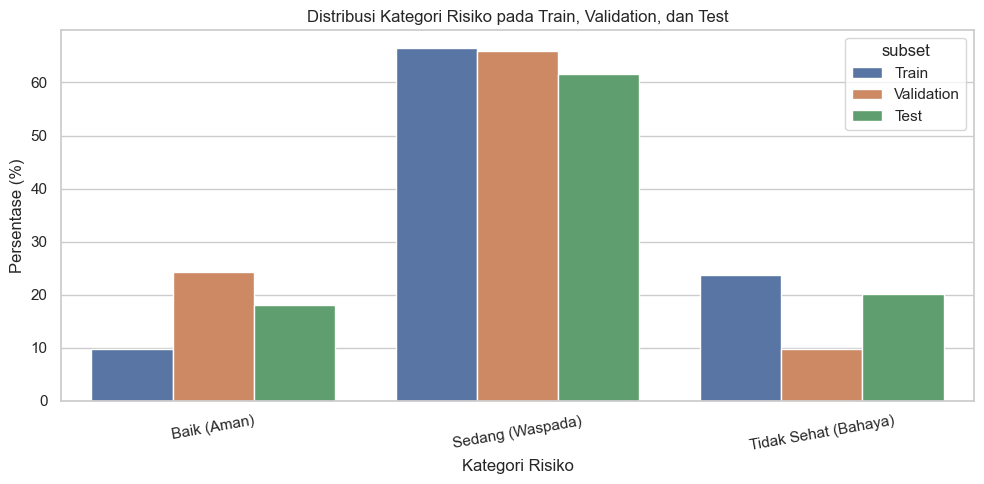

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribusi_split,
    x="kategori",
    y="persentase",
    hue="subset"
)

plt.title("Distribusi Kategori Risiko pada Train, Validation, dan Test")
plt.xlabel("Kategori Risiko")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [42]:
urutan_kategori = ["Baik (Aman)", "Sedang (Waspada)", "Tidak Sehat (Bahaya)"]
label_map = {k: i for i, k in enumerate(urutan_kategori)}

y_train_enc = y_train.map(label_map).values
y_val_enc   = y_val.map(label_map).values
y_test_enc  = y_test.map(label_map).values

print(label_map)
print("Train:", np.bincount(y_train_enc))
print("Val  :", np.bincount(y_val_enc))
print("Test :", np.bincount(y_test_enc))

{'Baik (Aman)': 0, 'Sedang (Waspada)': 1, 'Tidak Sehat (Bahaya)': 2}
Train: [10068 68590 24515]
Val  : [10556 28604  4275]
Test : [ 6338 21580  7068]


## **Fungsi evaluasi**

In [43]:
hasil = []

def evaluasi(nama, y_true, y_pred, subset="Validation"):
    rec = recall_score(y_true, y_pred, average=None, labels=[0, 1, 2], zero_division=0)
    f1c = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2], zero_division=0)
    hasil.append({
        "Model": nama,
        "Subset": subset,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Recall Baik": rec[0],
        "Recall Sedang": rec[1],
        "Recall Tidak Sehat": rec[2],
        "F1 Baik": f1c[0],
        "F1 Sedang": f1c[1],
        "F1 Tidak Sehat": f1c[2],
    })

def tampilkan_hasil():
    return (pd.DataFrame(hasil)
            .sort_values(["Subset", "Macro F1"], ascending=[True, False])
            .round(4))

## **Baseline**

In [44]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train_enc)
evaluasi("Dummy (mayoritas)", y_val_enc, dummy.predict(X_val))

def label_risiko(pm25):
    if pm25 <= 15:
        return "Baik (Aman)"
    elif pm25 <= 55:
        return "Sedang (Waspada)"
    return "Tidak Sehat (Bahaya)"

pred_persist = X_val["pm2_5"].apply(label_risiko).map(label_map).values
evaluasi("Persistence kategori", y_val_enc, pred_persist)

tampilkan_hasil()

,Model,Subset,Accuracy,Balanced Acc,Macro F1,Recall Baik,Recall Sedang,Recall Tidak Sehat,F1 Baik,F1 Sedang,F1 Tidak Sehat
1,Persistence kategori,Validation,0.8237,0.7673,0.7672,0.7759,0.8659,0.6601,0.7751,0.8661,0.6603
0,Dummy (mayoritas),Validation,0.6585,0.3333,0.2647,0.0000,1.0000,0.0000,0.0000,0.7941,0.0000


## **Define model**

In [45]:
def buat_model(nama, class_weight=None):
    if nama == "LightGBM":
        return LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=63,
            class_weight=class_weight, random_state=42, n_jobs=-1, verbose=-1
        )
    if nama == "ExtraTrees":
        return ExtraTreesClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight=class_weight, random_state=42, n_jobs=-1
        )
    if nama == "HistGB":
        return HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, random_state=42
        )

daftar_model = ["LightGBM", "ExtraTrees", "HistGB"]

## **Tanpa balancing**

In [46]:
model_tanpa = {}
for nama in daftar_model:
    m = buat_model(nama)
    m.fit(X_train, y_train_enc)
    model_tanpa[nama] = m
    evaluasi(f"{nama} | tanpa balancing", y_val_enc, m.predict(X_val))

tampilkan_hasil()

,Model,Subset,Accuracy,Balanced Acc,Macro F1,Recall Baik,Recall Sedang,Recall Tidak Sehat,F1 Baik,F1 Sedang,F1 Tidak Sehat
3,ExtraTrees | tanpa balancing,Validation,0.8643,0.7804,0.8135,0.7406,0.9406,0.6599,0.8005,0.9013,0.7388
2,LightGBM | tanpa balancing,Validation,0.8560,0.7525,0.7929,0.7346,0.9419,0.5811,0.7950,0.8960,0.6877
1,Persistence kategori,Validation,0.8237,0.7673,0.7672,0.7759,0.8659,0.6601,0.7751,0.8661,0.6603
4,HistGB | tanpa balancing,Validation,0.8420,0.7188,0.7658,0.6928,0.9454,0.5181,0.7697,0.8874,0.6404
0,Dummy (mayoritas),Validation,0.6585,0.3333,0.2647,0.0000,1.0000,0.0000,0.0000,0.7941,0.0000


## Class Weight

In [47]:
model_cw = {}
sw_train = compute_sample_weight("balanced", y_train_enc)

for nama in daftar_model:
    if nama == "HistGB":
        m = buat_model(nama)
        m.fit(X_train, y_train_enc, sample_weight=sw_train)
    else:
        m = buat_model(nama, class_weight="balanced")
        m.fit(X_train, y_train_enc)
    model_cw[nama] = m
    evaluasi(f"{nama} | class weight", y_val_enc, m.predict(X_val))

tampilkan_hasil()

,Model,Subset,Accuracy,Balanced Acc,Macro F1,Recall Baik,Recall Sedang,Recall Tidak Sehat,F1 Baik,F1 Sedang,F1 Tidak Sehat
6,ExtraTrees | class weight,Validation,0.8669,0.8176,0.8255,0.8266,0.9033,0.7228,0.8220,0.8994,0.7552
3,ExtraTrees | tanpa balancing,Validation,0.8643,0.7804,0.8135,0.7406,0.9406,0.6599,0.8005,0.9013,0.7388
5,LightGBM | class weight,Validation,0.8404,0.8312,0.8024,0.8794,0.8351,0.7792,0.8075,0.8733,0.7264
2,LightGBM | tanpa balancing,Validation,0.8560,0.7525,0.7929,0.7346,0.9419,0.5811,0.7950,0.8960,0.6877
7,HistGB | class weight,Validation,0.8253,0.8176,0.7859,0.8725,0.8171,0.7633,0.7904,0.8603,0.7069
1,Persistence kategori,Validation,0.8237,0.7673,0.7672,0.7759,0.8659,0.6601,0.7751,0.8661,0.6603
4,HistGB | tanpa balancing,Validation,0.8420,0.7188,0.7658,0.6928,0.9454,0.5181,0.7697,0.8874,0.6404
0,Dummy (mayoritas),Validation,0.6585,0.3333,0.2647,0.0000,1.0000,0.0000,0.0000,0.7941,0.0000


## SMOTE(hanya data train)

In [48]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train_enc)

print("Sebelum SMOTE:", np.bincount(y_train_enc))
print("Sesudah SMOTE:", np.bincount(y_train_sm))

model_sm = {}
for nama in daftar_model:
    m = buat_model(nama)  # tanpa class weight karena data sudah seimbang
    m.fit(X_train_sm, y_train_sm)
    model_sm[nama] = m
    evaluasi(f"{nama} | SMOTE", y_val_enc, m.predict(X_val))

tampilkan_hasil()

Sebelum SMOTE: [10068 68590 24515]
Sesudah SMOTE: [68590 68590 68590]


,Model,Subset,Accuracy,Balanced Acc,Macro F1,Recall Baik,Recall Sedang,Recall Tidak Sehat,F1 Baik,F1 Sedang,F1 Tidak Sehat
6,ExtraTrees | class weight,Validation,0.8669,0.8176,0.8255,0.8266,0.9033,0.7228,0.8220,0.8994,0.7552
3,ExtraTrees | tanpa balancing,Validation,0.8643,0.7804,0.8135,0.7406,0.9406,0.6599,0.8005,0.9013,0.7388
9,ExtraTrees | SMOTE,Validation,0.8367,0.8486,0.8040,0.8996,0.8143,0.8318,0.8061,0.8679,0.7379
5,LightGBM | class weight,Validation,0.8404,0.8312,0.8024,0.8794,0.8351,0.7792,0.8075,0.8733,0.7264
2,LightGBM | tanpa balancing,Validation,0.8560,0.7525,0.7929,0.7346,0.9419,0.5811,0.7950,0.8960,0.6877
8,LightGBM | SMOTE,Validation,0.8347,0.7905,0.7879,0.8204,0.8618,0.6894,0.7862,0.8730,0.7044
7,HistGB | class weight,Validation,0.8253,0.8176,0.7859,0.8725,0.8171,0.7633,0.7904,0.8603,0.7069
10,HistGB | SMOTE,Validation,0.8253,0.7693,0.7728,0.8156,0.8574,0.6351,0.7746,0.8661,0.6778
1,Persistence kategori,Validation,0.8237,0.7673,0.7672,0.7759,0.8659,0.6601,0.7751,0.8661,0.6603
4,HistGB | tanpa balancing,Validation,0.8420,0.7188,0.7658,0.6928,0.9454,0.5181,0.7697,0.8874,0.6404


## Perbandingan

,Model,Accuracy,Balanced Acc,Macro F1,Recall Baik,Recall Tidak Sehat
6,ExtraTrees | class weight,0.8669,0.8176,0.8255,0.8266,0.7228
3,ExtraTrees | tanpa balancing,0.8643,0.7804,0.8135,0.7406,0.6599
9,ExtraTrees | SMOTE,0.8367,0.8486,0.8040,0.8996,0.8318
5,LightGBM | class weight,0.8404,0.8312,0.8024,0.8794,0.7792
2,LightGBM | tanpa balancing,0.8560,0.7525,0.7929,0.7346,0.5811
8,LightGBM | SMOTE,0.8347,0.7905,0.7879,0.8204,0.6894
7,HistGB | class weight,0.8253,0.8176,0.7859,0.8725,0.7633
10,HistGB | SMOTE,0.8253,0.7693,0.7728,0.8156,0.6351
1,Persistence kategori,0.8237,0.7673,0.7672,0.7759,0.6601
4,HistGB | tanpa balancing,0.8420,0.7188,0.7658,0.6928,0.5181


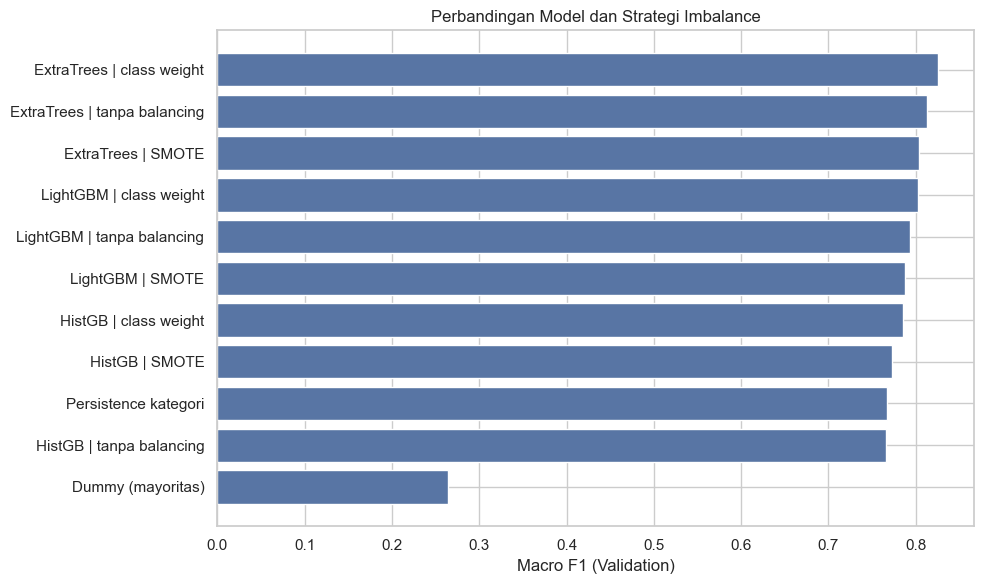

In [49]:
df_hasil = tampilkan_hasil()
df_val = df_hasil[df_hasil["Subset"] == "Validation"]

display(df_val[["Model", "Accuracy", "Balanced Acc", "Macro F1",
                "Recall Baik", "Recall Tidak Sehat"]])

plt.figure(figsize=(10, 6))
d = df_val.sort_values("Macro F1")
plt.barh(d["Model"], d["Macro F1"], color="#5875a4")
plt.xlabel("Macro F1 (Validation)")
plt.title("Perbandingan Model dan Strategi Imbalance")
plt.tight_layout()
plt.show()

## Memilih model terbaik

In [50]:
df_ml = df_val[df_val["Model"].str.contains(r"\|")]
terbaik = df_ml.sort_values("Macro F1", ascending=False).iloc[0]

print("Model terbaik:", terbaik["Model"])
print(terbaik[["Macro F1", "Balanced Acc", "Recall Baik", "Recall Tidak Sehat"]])

# Bandingkan dengan baseline
print("\nMacro F1 baseline:")
display(df_val[~df_val["Model"].str.contains(r"\|")][["Model", "Macro F1"]])

semua_model = {
    "tanpa balancing": model_tanpa,
    "class weight": model_cw,
    "SMOTE": model_sm,
}
nama_model, strategi = [s.strip() for s in terbaik["Model"].split("|")]
model_final = semua_model[strategi][nama_model]

Model terbaik: ExtraTrees | class weight
Macro F1              0.8255
Balanced Acc          0.8176
Recall Baik           0.8266
Recall Tidak Sehat    0.7228
Name: 6, dtype: object

Macro F1 baseline:


,Model,Macro F1
1,Persistence kategori,0.7672
0,Dummy (mayoritas),0.2647


## **Evaluasi akhir**

                      precision    recall  f1-score   support

         Baik (Aman)     0.8141    0.7517    0.7816      6338
    Sedang (Waspada)     0.8551    0.9006    0.8773     21580
Tidak Sehat (Bahaya)     0.8344    0.7562    0.7934      7068

            accuracy                         0.8445     34986
           macro avg     0.8345    0.8028    0.8174     34986
        weighted avg     0.8435    0.8445    0.8430     34986



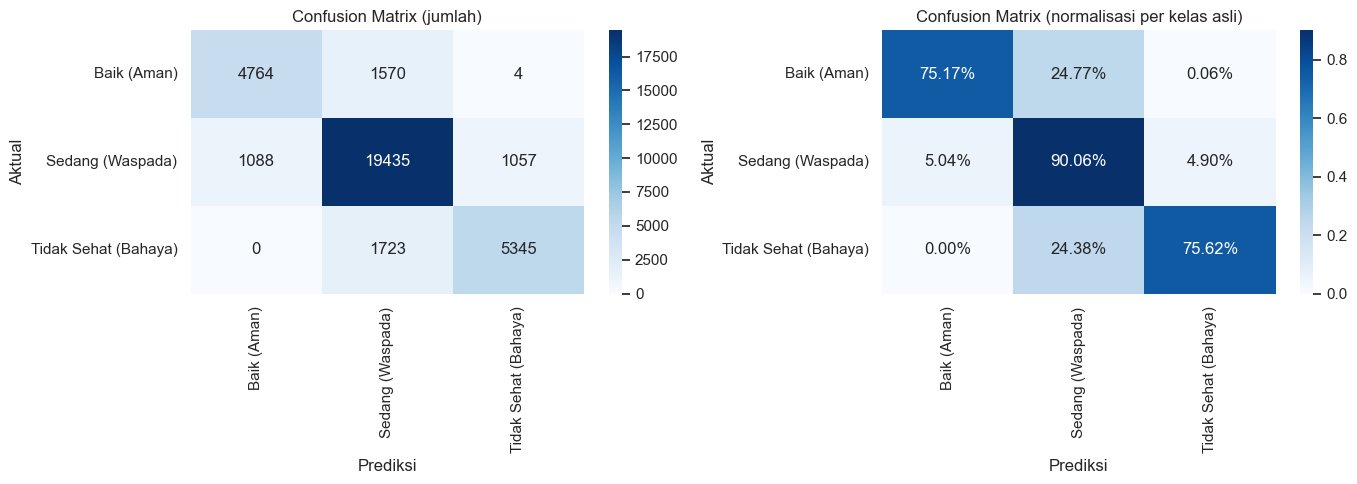

In [51]:
y_pred_test = model_final.predict(X_test)
evaluasi(f"{terbaik['Model']} (FINAL)", y_test_enc, y_pred_test, subset="Test")

print(classification_report(
    y_test_enc, y_pred_test,
    target_names=urutan_kategori, digits=4, zero_division=0
))

cm = confusion_matrix(y_test_enc, y_pred_test)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=urutan_kategori, yticklabels=urutan_kategori)
ax[0].set_title("Confusion Matrix (jumlah)")
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", ax=ax[1],
            xticklabels=urutan_kategori, yticklabels=urutan_kategori)
ax[1].set_title("Confusion Matrix (normalisasi per kelas asli)")
for a in ax:
    a.set_xlabel("Prediksi")
    a.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

## **Feature Importance**

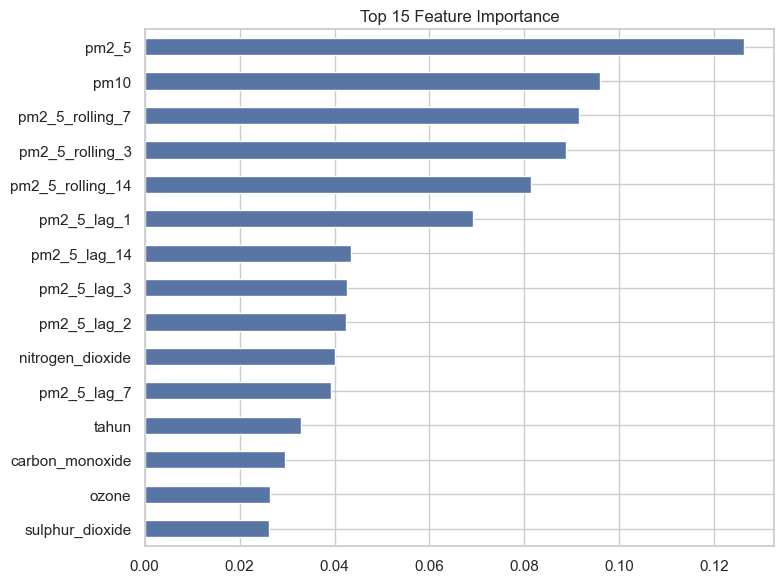

In [52]:
if hasattr(model_final, "feature_importances_"):
    imp = pd.Series(model_final.feature_importances_, index=fitur_model)
    imp.sort_values().tail(15).plot(kind="barh", figsize=(8, 6), color="#5875a4")
    plt.title("Top 15 Feature Importance")
    plt.tight_layout()
    plt.show()
else:
    from sklearn.inspection import permutation_importance
    r = permutation_importance(model_final, X_val, y_val_enc,
                               scoring="f1_macro", n_repeats=5,
                               random_state=42, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=fitur_model)
    imp.sort_values().tail(15).plot(kind="barh", figsize=(8, 6), color="#5875a4")
    plt.title("Top 15 Permutation Importance (HistGB)")
    plt.tight_layout()
    plt.show()